# Neural Boltzmann Machines

Neural Boltzmann Machines come to help when we need generative RBMs conditioned on an input type. But before developing the idea of Neural Boltzmann Machines lets think how we can simply achieve that. 

The goal is to develop a generative model that will generate MNIST style digits given the input label.

### Initial Idea: Train a RBM for each digit

Very simple, we will train an ensemble of RBMs with each one of them trained on pictures of one specific digit.

torch.Size([60000, 784])


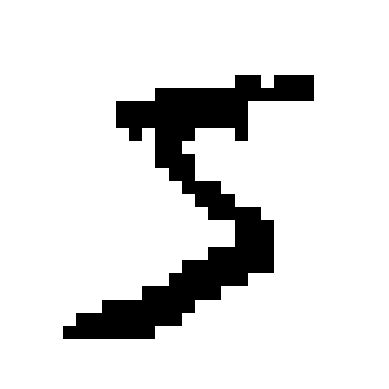

In [26]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
)

# Binarize and flatten: pixel / 255 > 0.5 equals pixel > 127.5
X_train = (train_data.data > 127.5).float().reshape(-1, 784)

print(X_train.shape)  # torch.Size([60000, 784])

# Plot an example
plt.imshow(1 - X_train[0].reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()

### Split the data to digit groups

total number of digit 0: 5923
total number of digit 1: 6742
total number of digit 2: 5958
total number of digit 3: 6131
total number of digit 4: 5842
total number of digit 5: 5421
total number of digit 6: 5918
total number of digit 7: 6265
total number of digit 8: 5851
total number of digit 9: 5949


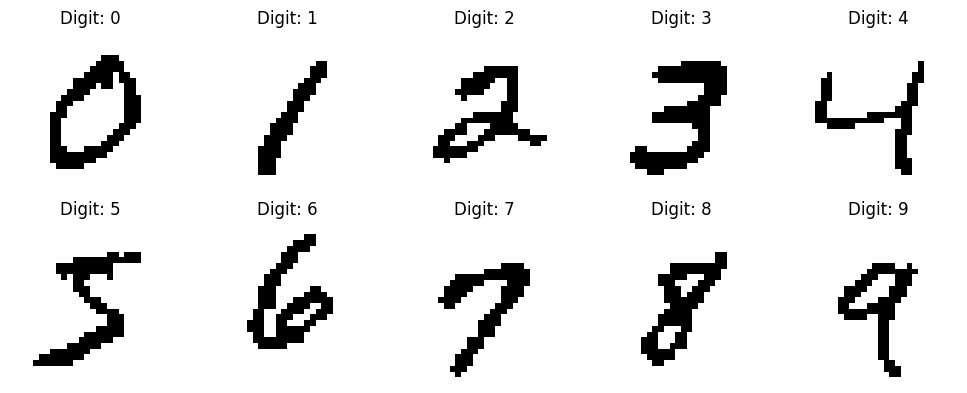

In [27]:
y_train = train_data.targets
digits = {digit: X_train[y_train == digit] for digit in range(10)}

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    # Convert each flattened image back to 28 × 28
    print(f"total number of digit {i}: {len(digits[i])}")
    ax.imshow(1 - digits[i][0].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Digit: {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
def sigmoid(x):
    return torch.sigmoid(x)

def hidden_probabilities(v, W, b_h):
    """P(h=1 | v): accepts [N] or [batch, N], returns [M] or [batch, M]."""
    return sigmoid(v @ W + b_h)

def visible_probabilities(h, W, b_v):
    """P(v=1 | h): accepts [M] or [batch, M], returns [N] or [batch, N]."""
    return sigmoid(h @ W.T + b_v)

@torch.no_grad()
def Block_Gibbs_sampling(v, W, b_v, b_h, n):
    """Perform n Gibbs steps for one visible state or a batch of states."""
    for _ in range(n):
        # Sample hidden states conditioned on visible states.
        h = torch.bernoulli(hidden_probabilities(v, W, b_h))
        # Sample visible states conditioned on hidden states.
        v = torch.bernoulli(visible_probabilities(h, W, b_v))
    return v

@torch.no_grad()
def persistent_gibbs_sampling(v_set, W, b_v, b_h, n=20):
    """Advance persistent visible chains of shape [num_chains, N]."""
    samples = Block_Gibbs_sampling(v_set, W, b_v, b_h, n)
    # Draw hidden states conditioned on the final visible states.
    samples_h = torch.bernoulli(hidden_probabilities(samples, W, b_h))
    return samples, samples_h



In [29]:
def vh_data(v_set, W, b_h):
    """Data expectation <v_i h_mu>: [batch, N] -> [N, M]."""
    return (v_set.T @ hidden_probabilities(v_set, W, b_h)) / len(v_set)

def v_data(v_set, W, b_h):
    """Data expectation <v_i>: [batch, N] -> [N]."""
    return v_set.mean(dim=0)

def h_data(v_set, W, b_h):
    """Data expectation <h_mu>: [batch, N] -> [M]."""
    return hidden_probabilities(v_set, W, b_h).mean(dim=0)

def vh_model(samples, samples_h):
    """Model expectation <v_i h_mu>, averaged over persistent chains."""
    return (samples.T @ samples_h) / len(samples)

def v_model(samples):
    return samples.mean(dim=0)

def h_model(samples_h):
    return samples_h.mean(dim=0)

### Training setup

In [30]:
N, M = 784, 32
batch_size = 256
num_epochs = 50
learning_rate = 0.25

W_list = []
a_list = []
b_list = []

for i in range(10):
    print("Training RBM for digit:", i)
    train_batches = DataLoader(digits[i], batch_size=batch_size, shuffle=True) # type: ignore

    # Initialize parameters again for training
    W = 0.01 * torch.randn(N, M, device=device)
    a = torch.zeros(N, device=device)
    b = torch.zeros(M, device=device)

    # Initialize persistent chains only once, outside both training loops.
    samples = torch.bernoulli(
        torch.full((batch_size, N), 0.5, device=device)
    )

    history = []

    with torch.no_grad():
        for epoch in range(num_epochs):
            total_errors = torch.zeros(3, device=device)
            num_examples = 0

            for v_batch in train_batches:
                v_batch = v_batch.to(device)

                samples, samples_h = persistent_gibbs_sampling(samples, W, a, b, 100)

                err_W = vh_data(v_batch, W, b) - vh_model(samples, samples_h)
                err_a = v_data(v_batch, W, b) - v_model(samples)
                err_b = h_data(v_batch, W, b) - h_model(samples_h)

                W += learning_rate * err_W
                a += learning_rate * err_a
                b += learning_rate * err_b

                batch_n = len(v_batch)
                total_errors += batch_n * torch.stack([
                    err_W.norm(), err_a.norm(), err_b.norm()
                ])
                num_examples += batch_n

            mean_errors = (total_errors / num_examples).cpu().tolist()
            history.append(mean_errors)

            if epoch == 0 or epoch == num_epochs - 1:
                print(
                        f"Epoch {epoch + 1:3d}/{num_epochs} | "
                        f"W update norm: {mean_errors[0]:.4f} | "
                        f"a update norm: {mean_errors[1]:.4f} | "
                        f"b update norm: {mean_errors[2]:.4f}"
                    )
                
    W_list.append(W)
    a_list.append(a)
    b_list.append(b)

Training RBM for digit: 0
Epoch   1/50 | W update norm: 21.4986 | a update norm: 5.1150 | b update norm: 1.4254
Epoch  50/50 | W update norm: 7.0961 | a update norm: 1.6008 | b update norm: 0.5885
Training RBM for digit: 1
Epoch   1/50 | W update norm: 9.6142 | a update norm: 3.3172 | b update norm: 0.9644
Epoch  50/50 | W update norm: 8.4422 | a update norm: 1.9338 | b update norm: 0.9486
Training RBM for digit: 2
Epoch   1/50 | W update norm: 20.4739 | a update norm: 5.5653 | b update norm: 1.5930
Epoch  50/50 | W update norm: 10.1280 | a update norm: 2.3692 | b update norm: 0.8339
Training RBM for digit: 3
Epoch   1/50 | W update norm: 22.7002 | a update norm: 5.5702 | b update norm: 1.5910
Epoch  50/50 | W update norm: 14.4824 | a update norm: 3.2869 | b update norm: 1.1439
Training RBM for digit: 4
Epoch   1/50 | W update norm: 14.1739 | a update norm: 4.6884 | b update norm: 1.6213
Epoch  50/50 | W update norm: 9.4737 | a update norm: 2.1245 | b update norm: 0.8582
Training RBM f

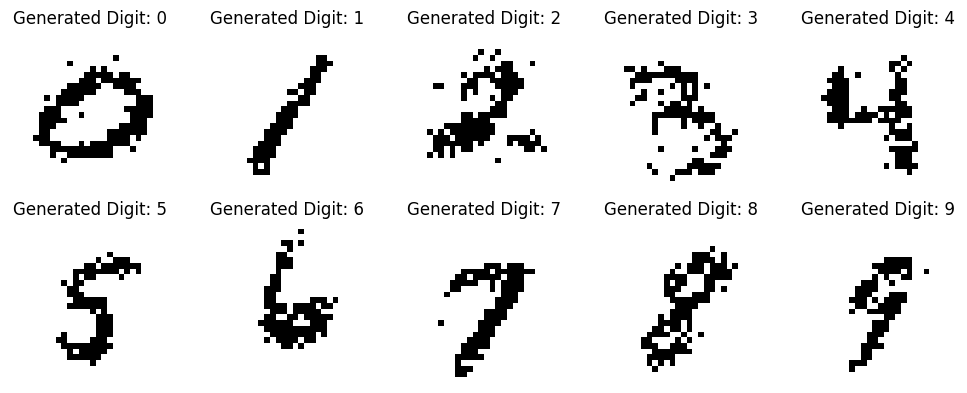

In [31]:
# Visualize a Samples
v0 = torch.bernoulli(torch.full((N,), 0.5, device=device))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    v_sample = Block_Gibbs_sampling(v0, W_list[i], a_list[i], b_list[i], 10000)
    ax.imshow(1 - v_sample.cpu().reshape(28, 28), cmap="gray")
    ax.set_title(f"Generated Digit: {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Results

This method successfully captures generative model of each digit by assigning a RBM to each one. However, the learned RBMs are independent of each other so they do not provide any information about how one distribution is related to another, or if there are any representation relationship among the common features of the digits.

### Neural Boltzmann Machines

Now we want to learn one conditional distribution model $P(image|digit)$. The trick is straigtforward: the parameters of the RBM will be generated by functions that takes digit label as input. We will use neural networks to learn those functions which will know the representation of the RBM parameters given label condition. The resulting ***Neural Boltzmann Machine*** is given by:

$$
E(\mathbf v,\mathbf h | x)
=-\mathbf a_{\phi}(x)^T\mathbf v-\mathbf b_{\chi}(x)^T\mathbf h-\mathbf v^T\mathbf W_{\psi}(x)\mathbf h
$$

The training of this model is straigforward. Recall the MLE gradients:

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial a_i}
=\langle v_i\rangle_{\mathrm{data}}
-\langle v_i\rangle_{\mathrm{model}},\\[5mm]
\frac{\partial\mathcal L}{\partial b_\mu}
=\langle h_\mu\rangle_{\mathrm{data}}
-\langle h_\mu\rangle_{\mathrm{model}},\\[5mm]
\frac{\partial\mathcal L}{\partial W_{i\mu}}
=\langle v_i h_\mu\rangle_{\mathrm{data}}
-\langle v_i h_\mu\rangle_{\mathrm{model}}
\end{aligned}
$$

By simple chain rule now the new likelihood gradients will be:

$$
\begin{aligned}
\frac{\partial\mathcal L}{\partial \phi} = \sum_i \frac{\partial\mathcal L}{\partial a_i} \frac{\partial a_i}{\partial \phi},\\[5mm]
\frac{\partial\mathcal L}{\partial \chi} = \sum_i \frac{\partial\mathcal L}{\partial b_i} \frac{\partial b_i}{\partial \chi},\\[5mm]
\frac{\partial\mathcal L}{\partial \psi} = \sum_{i\mu} \frac{\partial\mathcal L}{\partial W_{i\mu}} \frac{\partial W_{i\mu}}{\partial \psi}
\end{aligned}
$$

Hence we will use these new gradients to update our network parameters

In [32]:
from torch import nn

In [33]:
def make_net(output_dim):
    return nn.Sequential(
        nn.Linear(1, 32),
        nn.ReLU(),
        nn.Linear(32, 32),
        nn.ReLU(),
        nn.Linear(32, output_dim),
    )


class NeuralRBM(nn.Module):
    def __init__(self, num_vis, num_hid):
        super().__init__()
        self.num_vis = num_vis
        self.num_hid = num_hid

        self.a_net = make_net(num_vis)
        self.b_net = make_net(num_hid)
        self.W_net = make_net(num_vis * num_hid)

    def forward(self, z):
        # z (digit labels): [batch_size, 1]
        a = self.a_net(z)
        b = self.b_net(z)
        W = self.W_net(z).reshape(-1, self.num_vis, self.num_hid)
        return a, b, W

In [43]:
N, M = 784, 64
batch_size = 256
num_epochs = 20
learning_rate = 0.5e-2

train_dataset = TensorDataset(X_train, y_train)
train_batches = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
)

# Initialize parameter generating model and optimizer
model = NeuralRBM(N, M).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# One persistent chain per digit
# Keep a batch dimension of size 1 for the existing helpers
samples = torch.bernoulli(
    torch.full((10, 1, N), 0.5, device=device)
)

# Float inputs of shape [10, 1] for the parameter networks
digit_inputs = torch.arange(10, device=device).float().unsqueeze(1)

history = []
model.train()
for epoch in range(num_epochs):
    total_errors = torch.zeros(3, device=device)
    num_examples = 0

    for v_batch, labels in train_batches:
        v_batch = v_batch.to(device)
        labels = labels.to(device)  # [batch_size]
        batch_n = len(v_batch)

        optimizer.zero_grad()

        # Generate RBM parameters for all ten digits
        a_all, b_all, W_all = model(digit_inputs)
        loss = torch.zeros((), device=device)

        for digit in labels.unique().tolist():
            v_digit = v_batch[labels == digit]
            digit_n = len(v_digit)

            a = a_all[digit]
            b = b_all[digit]
            W = W_all[digit]

            # Estimate MLE gradients without differentiating
            with torch.no_grad():
                samples[digit], samples_h = persistent_gibbs_sampling(samples[digit], W, a, b, 100)
                err_W = vh_data(v_digit, W, b) - vh_model(samples[digit], samples_h)
                err_a = v_data(v_digit, W, b) - v_model(samples[digit])
                err_b = h_data(v_digit, W, b) - h_model(samples_h)

                total_errors += digit_n * torch.stack([
                    err_W.norm(), err_a.norm(), err_b.norm()
                ])

            # Surrogate loss: backpropagate the MLE gradients
            # Weight each digit by its frequency in this batch
            # MLE grad losses will be treated as constants and propagate through network
            loss -= (digit_n / batch_n) * (
                (W * err_W).sum()
                + (a * err_a).sum()
                + (b * err_b).sum()
            )

        loss.backward()
        optimizer.step()
        num_examples += batch_n

    mean_errors = (total_errors / num_examples).cpu().tolist()
    history.append(mean_errors)

    if epoch == 0 or epoch == num_epochs - 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{num_epochs} | "
            f"W gradient norm: {mean_errors[0]:.4f} | "
            f"a gradient norm: {mean_errors[1]:.4f} | "
            f"b gradient norm: {mean_errors[2]:.4f}"
        )

Epoch   1/20 | W gradient norm: 50.8205 | a gradient norm: 8.7282 | b gradient norm: 3.1567
Epoch   6/20 | W gradient norm: 45.0709 | a gradient norm: 8.0662 | b gradient norm: 3.6466
Epoch  11/20 | W gradient norm: 44.8965 | a gradient norm: 7.9301 | b gradient norm: 3.6079
Epoch  16/20 | W gradient norm: 44.4411 | a gradient norm: 7.8740 | b gradient norm: 3.5772
Epoch  20/20 | W gradient norm: 44.8750 | a gradient norm: 7.8768 | b gradient norm: 3.6069


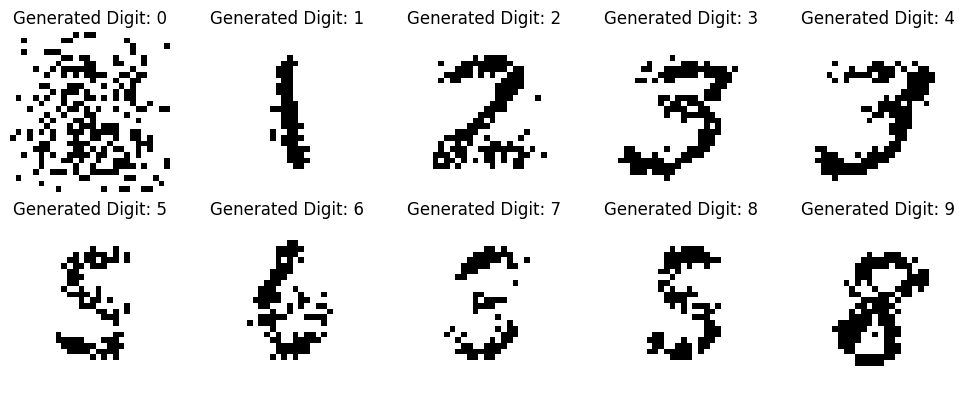

In [46]:
# Visualize a Samples
v0 = torch.bernoulli(torch.full((N,), 0.5, device=device))
a_all, b_all, W_all = model(digit_inputs)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    v_sample = Block_Gibbs_sampling(v0, W_all[i], a_all[i], b_all[i], 10000)
    ax.imshow(1 - v_sample.cpu().reshape(28, 28), cmap="gray")
    ax.set_title(f"Generated Digit: {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()